# パーセプトロン実験ノートブック：距離・内積・勾配・収束定理

**目標**：教科書の距離の公式 $r_k=|g(x_k)|/\|w\|$ と、更新式 $w\leftarrow w+\rho b_k x_k$ が**なぜ成立し、なぜ有効か**を、自分の手で数値・図・学習ログから確認する。

1. 決定境界までの距離と直交射影
2. 内積によるスコアの改善と更新方向
3. パーセプトロン損失と勾配・劣勾配
4. 5個のデータで学習を1処理ずつ追跡
5. パーセプトロン収束定理とマージン
6. 学習率・初期値・非分離データの比較
7. 双対形式とグラム行列

> Python / NumPy / Matplotlib で動作。外部データやGPUは不要。上から順番に実行してください。乱数を使う実験ではシードを固定しています。

[学習記録と実行方法](../README.md)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['font.size'] = 11
rng = np.random.default_rng(42)
print('NumPy:', np.__version__)
print('実験準備完了')

NumPy: 2.0.2
実験準備完了


## 実験1：決定境界までの距離と射影

識別関数 $g(x)=w_0+w^Tx$ の決定境界は $g(x)=0$。$w\ne0$ は超平面に垂直（法線）です。

境界上の任意の点を $x_0$ とすると、$w^Tx_0=-w_0$ より

$$
\frac{|w^T(x_k-x_0)|}{\|w\|}
=\frac{|w^Tx_k+w_0|}{\|w\|}
=\boxed{\frac{|g(x_k)|}{\|w\|}}.
$$

射影の仕組み：単位法線 $n=w/\|w\|$ に対する **符号付き射影長** は $n^T(x_k-x_0)$、幾何学的な距離はその絶対値です。

なお垂線の足は $h=x_k-\frac{g(x_k)}{\|w\|^2}w$ と計算できます。

g(xk) = 10.0   ||w|| = 5.0
垂線の足 h = [2.8 0.4]   g(h) = -1.7763568394002505e-15
公式による距離 = 2.0
射影による距離 = 2.0
垂線の足までの距離 = 2.0


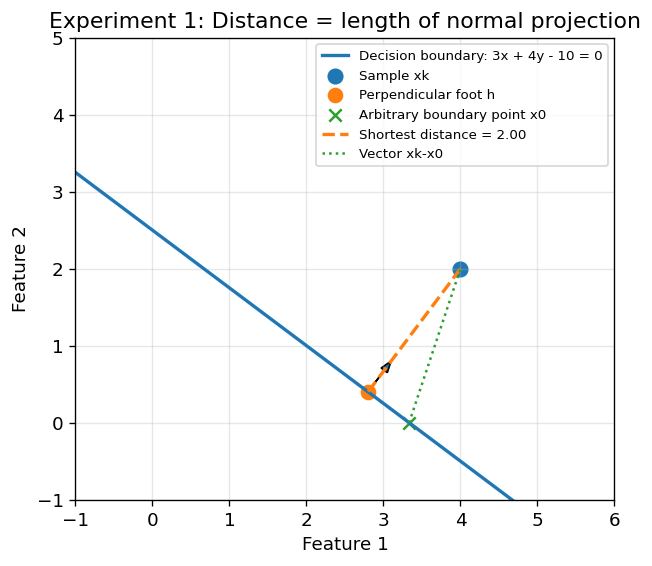

In [2]:
w = np.array([3.0, 4.0])
w0 = -10.0
xk = np.array([4.0, 2.0])
x0 = np.array([10.0/3.0, 0.0])  # 境界上の任意の点
g = lambda x: w0 + np.dot(w, x)
foot = xk - g(xk) * w / np.dot(w, w)
formula_distance = abs(g(xk)) / np.linalg.norm(w)
projection_distance = abs(np.dot(w/np.linalg.norm(w), xk-x0))
actual_distance = np.linalg.norm(xk-foot)
print('g(xk) =', g(xk), '  ||w|| =', np.linalg.norm(w))
print('垂線の足 h =', foot, '  g(h) =', g(foot))
print('公式による距離 =', formula_distance)
print('射影による距離 =', projection_distance)
print('垂線の足までの距離 =', actual_distance)
assert np.allclose([formula_distance, projection_distance, actual_distance], 2)

fig, ax = plt.subplots(figsize=(7, 5))
xx = np.linspace(-1, 6, 250)
ax.plot(xx, (10-3*xx)/4, label='Decision boundary: 3x + 4y - 10 = 0', lw=2)
ax.scatter(*xk, s=75, label='Sample xk')
ax.scatter(*foot, s=70, label='Perpendicular foot h')
ax.scatter(*x0, s=55, marker='x', label='Arbitrary boundary point x0')
ax.plot([xk[0],foot[0]],[xk[1],foot[1]],'--',lw=2,label=f'Shortest distance = {actual_distance:.2f}')
ax.plot([x0[0],xk[0]],[x0[1],xk[1]],':',lw=1.5,label='Vector xk-x0')
ax.arrow(foot[0], foot[1], .5*w[0]/np.linalg.norm(w), .5*w[1]/np.linalg.norm(w), head_width=.1, length_includes_head=True)
ax.set(xlabel='Feature 1',ylabel='Feature 2',title='Experiment 1: Distance = length of normal projection',xlim=(-1,6),ylim=(-1,5))
ax.set_aspect('equal',adjustable='box'); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()

### 確認問題1

- $g(x_k)=10$ が距離10を意味しないのはなぜでしょう？
- 識別関数の $w,w_0$ を同じ正の定数で倍にすると、距離の値はどうなりますか？

次のセルでは実際に係数を変えて確認します。

In [3]:
for scale in [0.1, 1, 7]:
    w2, w02 = scale*w, scale*w0
    d = abs(w02 + w2@xk) / np.linalg.norm(w2)
    print(f'scale={scale:>4}: g(xk)={w02+w2@xk:>6.2f}, distance={d:.4f}')

scale= 0.1: g(xk)=  1.00, distance=2.0000
scale=   1: g(xk)= 10.00, distance=2.0000
scale=   7: g(xk)= 70.00, distance=2.0000


## 実験2：内積が更新効果を決める

誤分類された $(x_k,b_k)$ を、$w'=w+\rho b_kv$ で修正すると

$$b_kg'(x_k)-b_kg(x_k)=\rho\,v^Tx_k.$$

- $v^Tx_k>0$：正解方向へのスコアが改善
- $v^Tx_k=0$：その点のスコアは不変
- $v^Tx_k<0$：その点のスコアは悪化

**更新の長さ $\|v\|$ を固定したとき**、コーシー・シュワルツの不等式より $v\parallel x_k$（同じ向き）で最大改善になります。ここで言う「最もよい」は、**その点のスコア改善に関して**であり、全学習データの精度を最大化する保証ではありません。

初期スコア b(w·x) = -2.0
     aligned  inner_product=+2.2361  improvement=+1.1180
  45-deg-ish  inner_product=+1.5811  improvement=+0.7906
  orthogonal  inner_product=+0.0000  improvement=+0.0000
    opposite  inner_product=-2.2361  improvement=-1.1180


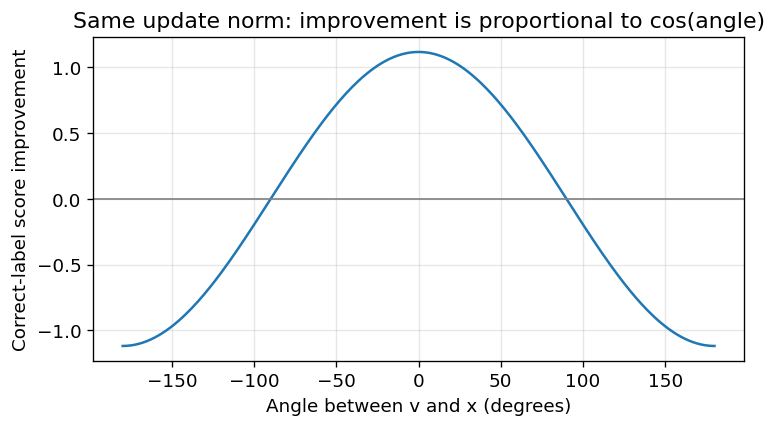

In [4]:
x = np.array([2., 1.])
b = +1
w_before = np.array([-1., 0.])  # 正クラスなのにスコア -2
rho = 0.5
unit = x/np.linalg.norm(x)
perp = np.array([-unit[1],unit[0]])
update_directions = {'aligned': unit, '45-deg-ish': (unit+perp)/np.sqrt(2),
                     'orthogonal': perp, 'opposite': -unit}
print('初期スコア b(w·x) =', b*(w_before@x))
for name,v in update_directions.items():
    after = w_before + rho*b*v
    improvement = b*(after@x)-b*(w_before@x)
    print(f'{name:>12}  inner_product={v@x:+.4f}  improvement={improvement:+.4f}')
    assert np.isclose(improvement, rho*(v@x))

angles = np.linspace(-np.pi, np.pi, 300)
cosines = rho*np.linalg.norm(x)*np.cos(angles)
fig,ax=plt.subplots(figsize=(7,3.5))
ax.plot(np.rad2deg(angles),cosines)
ax.axhline(0,color='gray',lw=1)
ax.set(xlabel='Angle between v and x (degrees)', ylabel='Correct-label score improvement',
       title='Same update norm: improvement is proportional to cos(angle)')
ax.grid(alpha=.3);plt.show()

### 「なぜ $x_k$ の定数倍を足すのか」への答え

標準更新 $w'=w+\rho b_kx_k$ は上の $v=x_k$ に対応し、

$$b_kg'(x_k)-b_kg(x_k)=\rho\|x_k\|^2>0\quad(x_k\neq0).$$

$\rho>0$ なら **別の定数でもよい**です。ただし1回の更新で必ず正しくなるわけではなく、別の学習点が悪化する場合もあります。

## 実験3：パーセプトロン損失と勾配

1個のデータに対するパーセプトロン損失を

$$L(w)=\max(0,-b_k w^Tx_k)$$

と定義します。$b_kw^Tx_k<0$ なら

$$\nabla_w L(w)=-b_kx_k,$$

勾配降下法 $w'=w-\rho\nabla L(w)$ はちょうど $w'=w+\rho b_kx_k$ になります。

**注意**：境界 $b_kw^Tx_k=0$ では、$x_k\ne 0$ のとき微分できません。$-b_kx_k$ は選択可能な劣勾配の1つで、教科書の「$\le0$ なら更新」という規則と整合します。

損失 L(w) = 2.0
解析的勾配 = [-2. -1.] 数値的勾配 = [-2. -1.]
rho=0.05: L(before)=2.00, L(after)=1.75, signed score=-1.75
rho=0.20: L(before)=2.00, L(after)=1.00, signed score=-1.00
rho=0.50: L(before)=2.00, L(after)=0.00, signed score=+0.50
rho=1.00: L(before)=2.00, L(after)=0.00, signed score=+3.00


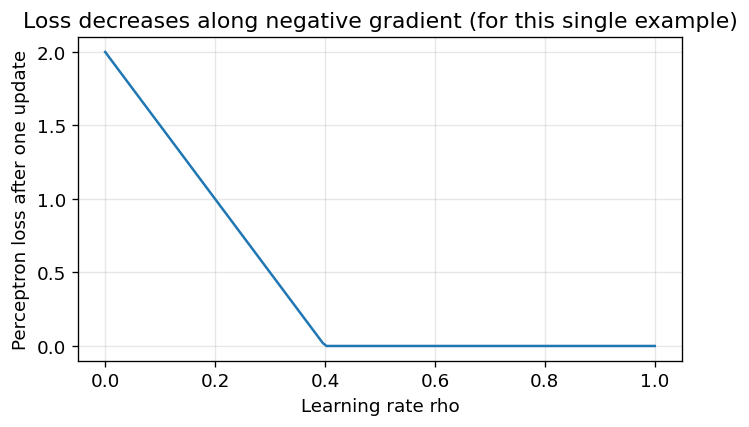

In [5]:
x = np.array([2., 1.]); b = 1.; w = np.array([-1., 0.])
loss = lambda ww: max(0.0, -b*(ww@x))
analytical_grad = -b*x
h=1e-6
finite_grad = np.array([(loss(w+h*np.eye(2)[i])-loss(w-h*np.eye(2)[i]))/(2*h) for i in range(2)])
print('損失 L(w) =', loss(w))
print('解析的勾配 =', analytical_grad, '数値的勾配 =', finite_grad)
assert np.allclose(finite_grad,analytical_grad,atol=1e-7)
for learning_rate in [0.05,0.2,0.5,1.0]:
    updated = w - learning_rate*analytical_grad
    print(f'rho={learning_rate:4.2f}: L(before)={loss(w):.2f}, L(after)={loss(updated):.2f}, signed score={b*(updated@x):+.2f}')

rhos=np.linspace(0,1,150)
fig,ax=plt.subplots(figsize=(6.5,3.5))
ax.plot(rhos,[loss(w-t*analytical_grad) for t in rhos])
ax.set(xlabel='Learning rate rho',ylabel='Perceptron loss after one update',title='Loss decreases along negative gradient (for this single example)')
ax.grid(alpha=.3);plt.show()

## 実験4：5個のデータで学習を完全追跡

以下の5点を使います。この実験では**切片なし**の線形識別 $g(x)=w^Tx$、初期重み $w=0$、$\rho=1$ です。

| データ | $x_k$ | 正解ラベル $b_k$ |
|---|---|---|
| 1 | $(2,0)$ | $+1$ |
| 2 | $(0,2)$ | $+1$ |
| 3 | $(-1,1)$ | $-1$ |
| 4 | $(-2,-1)$ | $-1$ |
| 5 | $(1,-2)$ | $-1$ |

更新条件は $b_kg(x_k)\le0$。各周の5点を順番に確認し、**更新のない1周**が終わったら停止します。

In [6]:
X = np.array([[2.,0.],[0.,2.],[-1.,1.],[-2.,-1.],[1.,-2.]])
y = np.array([1,1,-1,-1,-1])

def train_perceptron(X, y, rho=1.0, epochs=100, initial=None):
    w = np.zeros(X.shape[1]) if initial is None else np.array(initial,dtype=float).copy()
    history=[]; updates=0; converged=False
    for epoch in range(1,epochs+1):
        mistakes=0
        for i,(xi,bi) in enumerate(zip(X,y),start=1):
            before=w.copy(); score=float(w@xi); margin=float(bi*score)
            update=margin<=0
            if update:
                w += rho*bi*xi; updates+=1; mistakes+=1
            history.append(dict(epoch=epoch,index=i,score=score,margin=margin,update=update,
                                before=before,after=w.copy()))
        if mistakes==0:
            converged=True;break
    return w,history,updates,converged

w_final,history,updates,converged=train_perceptron(X,y)
print('最後の重み w =',w_final,'更新回数 =',updates,'収束 =',converged,'検査したエポック =',max(h['epoch'] for h in history))
print('\nepoch | point | b*g(x) before | update? | w before -> w after')
for h in history:
    print(f"{h['epoch']:>5} | {h['index']:>5} | {h['margin']:>13.1f} | {'YES' if h['update'] else ' no':>7} | {h['before']} -> {h['after']}")
assert np.allclose(w_final,[3,2]) and updates==5 and converged
assert np.all(y*(X@w_final)>0)

最後の重み w = [3. 2.] 更新回数 = 5 収束 = True 検査したエポック = 3

epoch | point | b*g(x) before | update? | w before -> w after
    1 |     1 |           0.0 |     YES | [0. 0.] -> [2. 0.]
    1 |     2 |           0.0 |     YES | [2. 0.] -> [2. 2.]
    1 |     3 |          -0.0 |     YES | [2. 2.] -> [3. 1.]
    1 |     4 |           7.0 |      no | [3. 1.] -> [3. 1.]
    1 |     5 |          -1.0 |     YES | [3. 1.] -> [2. 3.]
    2 |     1 |           4.0 |      no | [2. 3.] -> [2. 3.]
    2 |     2 |           6.0 |      no | [2. 3.] -> [2. 3.]
    2 |     3 |          -1.0 |     YES | [2. 3.] -> [3. 2.]
    2 |     4 |           8.0 |      no | [3. 2.] -> [3. 2.]
    2 |     5 |           1.0 |      no | [3. 2.] -> [3. 2.]
    3 |     1 |           6.0 |      no | [3. 2.] -> [3. 2.]
    3 |     2 |           4.0 |      no | [3. 2.] -> [3. 2.]
    3 |     3 |           1.0 |      no | [3. 2.] -> [3. 2.]
    3 |     4 |           8.0 |      no | [3. 2.] -> [3. 2.]
    3 |     5 |           1.0 |  

### 決定境界はどのように回転したか

更新した瞬間の $w$ を取り出し、$w^Tx=0$ を描きます。切片がなく重みが非ゼロの段階では、決定境界は原点を通ります。初期重みがゼロのときは全点でスコアがゼロになるため、境界線は描いていません。

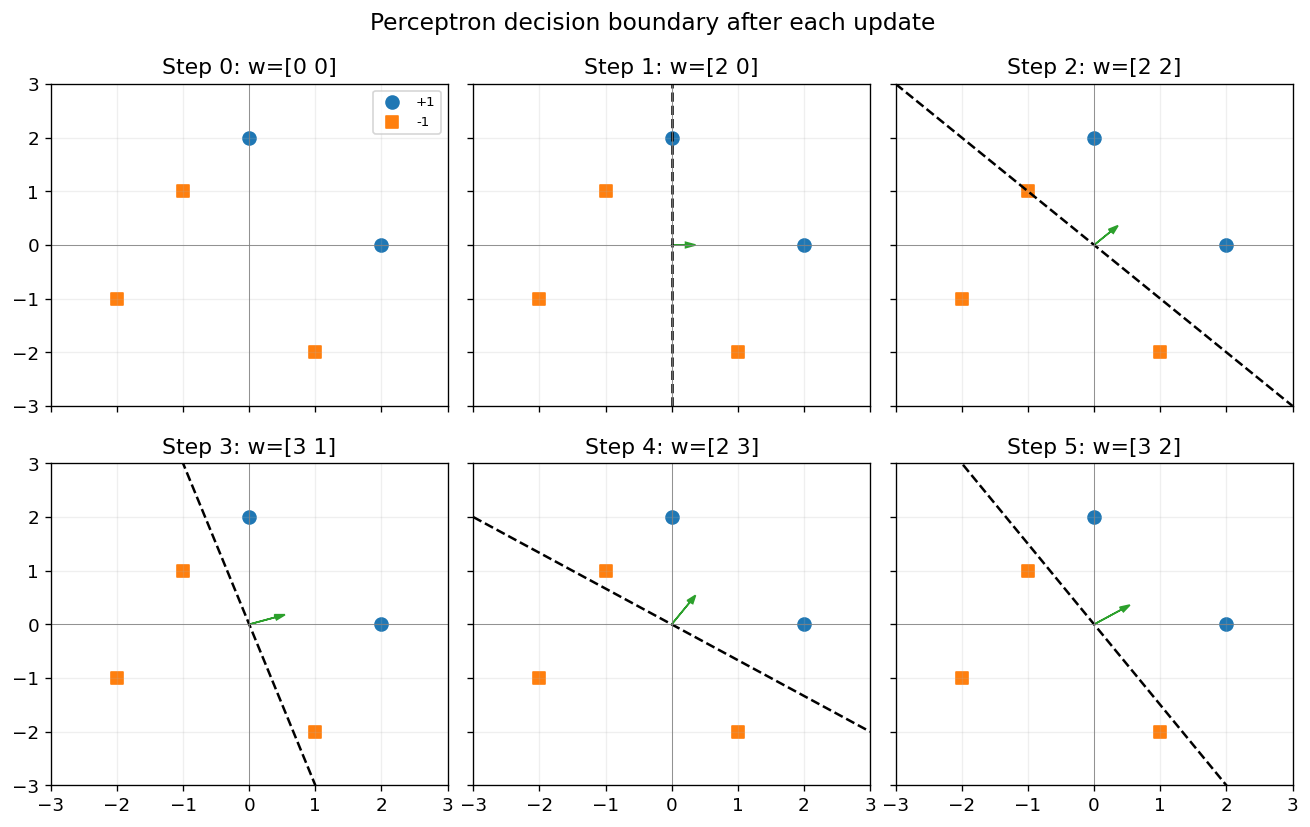

In [7]:
updates_list=[h for h in history if h['update']]
fig,axes=plt.subplots(2,3,figsize=(11,7),sharex=True,sharey=True)
stages=[np.zeros(2)]+[h['after'] for h in updates_list]
xx=np.linspace(-3,3,200)
for index,(ax,ww) in enumerate(zip(axes.flat,stages)):
    ax.scatter(X[y==1,0],X[y==1,1],c='tab:blue',s=60,label='+1')
    ax.scatter(X[y==-1,0],X[y==-1,1],c='tab:orange',s=60,marker='s',label='-1')
    if np.linalg.norm(ww)>0:
        if abs(ww[1])>1e-10: ax.plot(xx,-ww[0]/ww[1]*xx,'k--',lw=1.5)
        else: ax.axvline(0,color='k',ls='--')
        ax.arrow(0,0,ww[0]*.18,ww[1]*.18,head_width=.10,color='tab:green',length_includes_head=True)
    ax.set(title=f'Step {index}: w={ww.astype(int)}',xlim=(-3,3),ylim=(-3,3))
    ax.axhline(0,color='gray',lw=.5);ax.axvline(0,color='gray',lw=.5);ax.grid(alpha=.2)
axes[0,0].legend(loc='upper right',fontsize=8)
fig.suptitle('Perceptron decision boundary after each update',fontsize=14)
plt.tight_layout();plt.show()

## 実験5：パーセプトロンの収束定理

**定理（標準的な形）**：切片なしの学習データに対して、単位ベクトル $u$ と正数 $\gamma$ が存在し、すべての点で

$$b_i u^T x_i\ge\gamma>0,$$

かつ $\|x_i\|\le R$ なら、初期値 $w=0$、固定学習率 $\rho>0$ のパーセプトロンは有限回で停止し、誤分類・境界上での更新回数 $M$ は

$$\boxed{M\le (R/\gamma)^2}$$

を満たします。この上界は一般に緩いもので、エポック数ではなく**更新回数**に対する保証です。

**証明の核心**：$M$ 回の更新後、真の分離方向への射影は少なくとも $M\rho\gamma$ だけ増え、一方で $\|w_M\|^2\le M\rho^2R^2$。コーシー・シュワルツから

$$M\rho\gamma\le w_M^Tu\le\|w_M\|\le\rho R\sqrt{M}.$$

両辺を整理すると上界を得ます。

単位分離方向 u = [0.8321 0.5547]
各点の幾何学的な符号付きマージン = [1.6641 1.1094 0.2774 2.2188 0.2774]
gamma = 0.2773500981126146 R = 2.23606797749979
定理の更新上界 (R/gamma)^2 = 64.99999999999999
実際の更新回数 M = 5


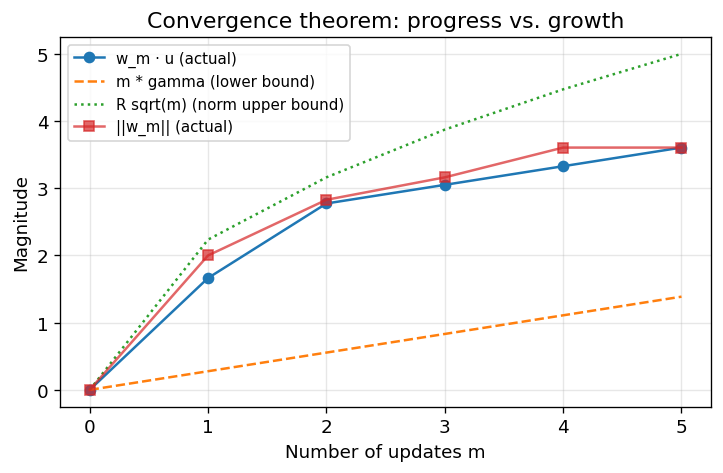

In [8]:
# 実際に見つかった分離方向 w_final / ||w_final|| は、定理の u の候補になる。
u = w_final/np.linalg.norm(w_final)
signed_projections = y*(X@u)
gamma = float(signed_projections.min())
R=float(np.linalg.norm(X,axis=1).max())
bound=(R/gamma)**2
print('単位分離方向 u =',u)
print('各点の幾何学的な符号付きマージン =',signed_projections)
print('gamma =',gamma,'R =',R)
print('定理の更新上界 (R/gamma)^2 =',bound)
print('実際の更新回数 M =',updates)
assert gamma>0 and updates<=bound+1e-10

# 各「更新直後」の進行をプロット
ws=[np.zeros(2)]+[h['after'] for h in updates_list]
progress=np.array([ww@u for ww in ws])
norms=np.array([np.linalg.norm(ww) for ww in ws])
ms=np.arange(len(ws))
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(ms,progress,'o-',label='w_m · u (actual)')
ax.plot(ms,ms*gamma,'--',label='m * gamma (lower bound)')
ax.plot(ms,R*np.sqrt(ms),':',label='R sqrt(m) (norm upper bound)')
ax.plot(ms,norms,'s-',alpha=.7,label='||w_m|| (actual)')
ax.set(xlabel='Number of updates m',ylabel='Magnitude',title='Convergence theorem: progress vs. growth')
ax.grid(alpha=.3);ax.legend(fontsize=9);plt.show()
assert np.all(progress+1e-9>=ms*gamma)
assert np.all(norms<=R*np.sqrt(ms)+1e-9)

### 収束定理の「距離」との関係

$u$ は長さ1なので、$b_i u^Tx_i$ は、原点を通る直線 $u^Tx=0$ までの**符号付き垂直距離**です。$\gamma$ はその最小値、つまり分離直線と学習データの最小距離（マージン）です。

$\gamma$ が大きく $R$ が小さいほど定理の上界は小さくなります。ただし、ここで求めた $\gamma$ は今回選んだ $u$ でのマージンであり、必ずしも最大マージンではありません。

## 実験6：学習率は別の定数でもよいのか？

初期重みが $0$、固定学習率 $\rho>0$、同一のデータ順序・更新判定なら、学習過程の重みは $\rho$ 倍になり、判定符号は変わりません。**更新回数も同じ**になります。ただし初期重みが非ゼロ、学習率が可変、正則化がある場合などには異なることがあります。

In [9]:
base=None
for rho in [0.1,0.5,1.,3.,10.]:
    ww,hh,mm,cc=train_perceptron(X,y,rho=rho)
    print(f'rho={rho:>4}: w={ww}, updates={mm}, converged={cc}, same classifier={np.all(y*(X@ww)>0)}')
    assert np.allclose(ww/rho,w_final) and mm==updates

rho= 0.1: w=[0.3 0.2], updates=5, converged=True, same classifier=True
rho= 0.5: w=[1.5 1. ], updates=5, converged=True, same classifier=True
rho= 1.0: w=[3. 2.], updates=5, converged=True, same classifier=True
rho= 3.0: w=[9. 6.], updates=5, converged=True, same classifier=True
rho=10.0: w=[30. 20.], updates=5, converged=True, same classifier=True


## 実験7：線形分離できない場合はどうなる？

同じ入力点 $x=(1,1)$ に $+1$ と $-1$ の矛盾するラベルを付けると、**どんな重みでも両方を正しく分類できません**。この場合、標準パーセプトロンには収束保証がありません。無限ループを避けるため、実験ではエポック数に上限を設けます。

converged = False updates = 24 epochs = 12
last w = [0. 0.]
更新後の重み（先頭8回）: [[1.0, 1.0], [0.0, 0.0], [1.0, 1.0], [0.0, 0.0], [1.0, 1.0], [0.0, 0.0], [1.0, 1.0], [0.0, 0.0]]


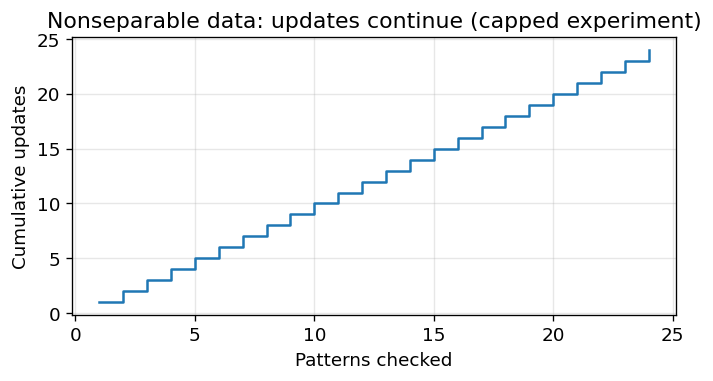

In [10]:
X_bad = np.array([[1.,1.],[1.,1.]])
y_bad = np.array([+1,-1])
w_bad,h_bad,m_bad,c_bad=train_perceptron(X_bad,y_bad,rho=1.,epochs=12)
print('converged =',c_bad,'updates =',m_bad,'epochs =',max(h['epoch'] for h in h_bad))
print('last w =',w_bad)
print('更新後の重み（先頭8回）:',[h['after'].tolist() for h in h_bad if h['update']][:8])
assert not c_bad

fig,ax=plt.subplots(figsize=(6.5,3))
ax.step(range(1,len(h_bad)+1),np.cumsum([h['update'] for h in h_bad]),where='post')
ax.set(xlabel='Patterns checked',ylabel='Cumulative updates',title='Nonseparable data: updates continue (capped experiment)')
ax.grid(alpha=.3);plt.show()

## 実験8：双対パーセプトロンとグラム行列

通常の内積カーネル $K(x_i,x_j)=x_i^Tx_j$ に対し、グラム行列 $G=XX^T$ を計算します（ここで $X$ の**各行**が1個のデータ）。

双対変数 $\alpha_i$ を使うと

$$w=\sum_i\alpha_i b_i x_i,\qquad g(x_j)=\sum_i\alpha_i b_i K(x_i,x_j).$$

誤分類した点、または境界上の点 $j$ の $\alpha_j$ を1増やすのは、主形式の $w\leftarrow w+b_jx_j$ に一致します。

In [11]:
G=X@X.T
alpha=np.zeros(len(X),dtype=int)
w=np.zeros(2)
dual_updates=[]
for epoch in range(1,101):
    epoch_updates=0
    for j in range(len(X)):
        score_dual=G[j]@(alpha*y)
        score_primal=w@X[j]
        assert np.isclose(score_dual,score_primal)
        if y[j]*score_dual<=0:
            alpha[j]+=1
            w+=y[j]*X[j]
            dual_updates.append((epoch,j+1,alpha.copy(),w.copy()))
            epoch_updates+=1
    if epoch_updates==0:break
print('Gram matrix:\n',G)
print('alpha =',alpha)
print('w from alpha =',(alpha*y)@X)
print('w from primal =',w)
print('updates =',len(dual_updates))
assert np.array_equal(alpha,[1,1,2,0,1])
assert np.allclose(w,w_final)

Gram matrix:
 [[ 4.  0. -2. -4.  2.]
 [ 0.  4.  2. -2. -4.]
 [-2.  2.  2.  1. -3.]
 [-4. -2.  1.  5.  0.]
 [ 2. -4. -3.  0.  5.]]
alpha = [1 1 2 0 1]
w from alpha = [3. 2.]
w from primal = [3. 2.]
updates = 5


## 自分で試す課題

1. **射影**：実験1の $w$ を $(1,2)$ に変え、$w_0$ を変えずに距離・垂線の足を計算する。
2. **学習方向**：実験2で更新方向 $v$ のノルムを固定し、角度を変える。改善幅がなぜコサインに比例するかを説明する。
3. **勾配**：実験3で学習率を大きくし、損失が0で止まる様子を確認する。
4. **学習過程**：実験4で学習データの順序を入れ替え、最終的な $w$・更新回数・マージンを比較する。
5. **収束定理**：実験5の $u$ を別の分離方向に変えると、$\gamma$ と理論上界はどう変わるか？
6. **非分離**：実験7を実行した際にどのような更新が繰り返されるかを説明する。

### 重要なまとめ

- **幾何学**：$|g(x)|/\|w\|$ は決定境界までの垂直距離。
- **内積**：更新がその点の正解方向スコアをどれだけ改善するかは $v^Tx$ で決まる。
- **勾配**：標準更新 $\rho bx$ はパーセプトロン損失の（劣）勾配降下に対応。
- **収束**：線形分離可能で正のマージンがあれば、有限回の更新で停止する。
- **双対性**：$w=\sum_i\alpha_i b_i x_i$ と書けるので、内積・カーネル行列だけで同じ学習ができる。